<a href="https://colab.research.google.com/github/sathyapv14/semi_supervised_classification/blob/main/semi_supervised_resnet18.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


# HyperVerge DL Assignment – Semi-supervised Image Classification (ResNet-18)

**Task:** 10-class animal classification (Animals-10, Italian class names) using only ResNet-18.
Phase 1 uses labelled data only; Phase 2 also uses unlabelled data.

| Class | English | Class | English |
|---|---|---|---|
| cane | dog | gatto | cat |
| cavallo | horse | mucca | cow |
| elefante | elephant | pecora | sheep |
| farfalla | butterfly | ragno | spider |
| gallina | chicken | scoiattolo | squirrel |

**Data:** 779 labelled images, 14,800 unlabelled images, 10,477 test images.
Stratified 80/20 train/validation split (seed 42).

## Final results

| Submission | Model | Rotated val acc | Rotated val mean per-class | Test acc |
|---|---|---|---|---|
| Phase 1 | ResNet-18, labelled data only (224×224) | 78.2% | 74.9% | **80.46%** |
| Phase 2 | Average of 3 ResNet-18s (Noisy Student student, rotation-robust teacher, Phase 1 model), 256×256 | 85.6% | 84.3% | **86.31%** |

All predictions use greyscale input and averaging over 4 rotations × horizontal flip.
Rotated validation predicted test accuracy within ~1–2 points.

## Key finding: domain shift between labelled and unlabelled data
- Labelled images are **greyscale and upright**; unlabelled (and test) images are **colour and rotated 90°/180°/270°**.
- Evidence: the Phase 1 model was 0.74 confident (median) on validation but only 0.27 on unlabelled
  images, and labelled 6,033 of 14,800 unlabelled images as "gatto" (cat).
- Impact: the Phase 1 model scores 90.4% on upright validation but 65.4% on rotated validation.
- Fix: greyscale all inputs, random 90° rotation augmentation, 4-rotation averaging at prediction time,
  and model selection on a rotated validation set (every validation image in all 4 orientations).

## Approach
**Phase 1:** ImageNet-pretrained ResNet-18, full fine-tuning, AdamW + one-cycle LR, label smoothing 0.1,
mixed precision, class-balanced sampling, 30 epochs. Checkpoint chosen by mean per-class accuracy.

**Phase 2 (Noisy Student self-training):**
1. Train a rotation-robust teacher on labelled data (greyscale + random rotations).
2. Teacher pseudo-labels the 14,800 unlabelled images (4-rotation averaging).
3. Class-relative selection: the most confident 50% of each predicted class, capped at 500
   → 4,893 pseudo-labels, ~500 per class, mean confidence 0.87.
4. Train a fresh ResNet-18 student on labelled (×3) + pseudo-labelled images with RandAugment and
   class-balanced sampling.
5. Final prediction averages the student, teacher and Phase 1 model, at 256×256 input.

## Experiment log
| Run | Change | Result |
|---|---|---|
| Phase 1 v1 | Pretrained ResNet-18, 15 epochs | 88.5% acc / 84.6% mean per-class (upright val); cat 60% |
| Phase 1 v2 | + class-balanced sampling, 30 epochs | 90.4% / 88.4% (upright val) |
| Phase 2 attempt 1 | Global confidence threshold for pseudo-labels | Kept 600 spiders, 0 squirrels; student worse than teacher |
| Phase 2 attempt 2 | Class-relative selection | Balanced counts, but student still worse → led to the domain-shift diagnosis |
| Phase 2 final | Greyscale + rotation fix, rotation-robust teacher | Student 81.3% vs teacher 77.2% mean per-class (rotated val) |
| Ensembles | Student + teacher; + Phase 1 model | 83.1% → 83.7% mean per-class; test 84.16% → 85.04% |
| Test-time resolution (Phase 2) | Predict at 256 instead of 224 (training used random crops, so objects looked larger) | Val 83.7% → 84.3% mean per-class; test 85.04% → 86.31% |
| Test-time resolution (Phase 1) | Phase 1 model alone at 256 vs 224 | Worse: 74.9% → 72.4% mean per-class – kept 224 |

## Challenges faced
1. **File paths:** the labels CSV held bare filenames while images sat in a subfolder → indexed all images by filename and asserted none were missing.
2. **Class imbalance:** overall accuracy hid a weak cat class (60%) → selected models by mean per-class accuracy and added class-balanced sampling.
3. **Pseudo-label imbalance:** confidence levels differ by class, so one global threshold starved some classes → switched to per-class ranking.
4. **Domain shift:** colour vs greyscale and rotated vs upright → greyscale, rotation augmentation, rotation-averaged prediction, rotated validation.

## Notes and assumptions
- ImageNet-pretrained ResNet-18 weights were used; only the provided labelled and unlabelled images were used for training. The test set was used only for prediction.
- The Phase 2 submission averages three ResNet-18 models; no other architectures were used.
- Considered but not done in the time: FixMatch-style consistency training, and rotation prediction as a self-supervised pretraining task.
- Reproducibility: seed 42, Colab T4 GPU; checkpoints saved in `hv_ckpt/` on Google Drive.

#Downloading the labeled and unlabeled data

#How to add the file to gdrive

1. Open the drive link shared
2. Click the three dots next to ***HV-AI-2025*** and select 'Make a copy'

DO NOT MANUALLY DOWNLOAD THE DATA.
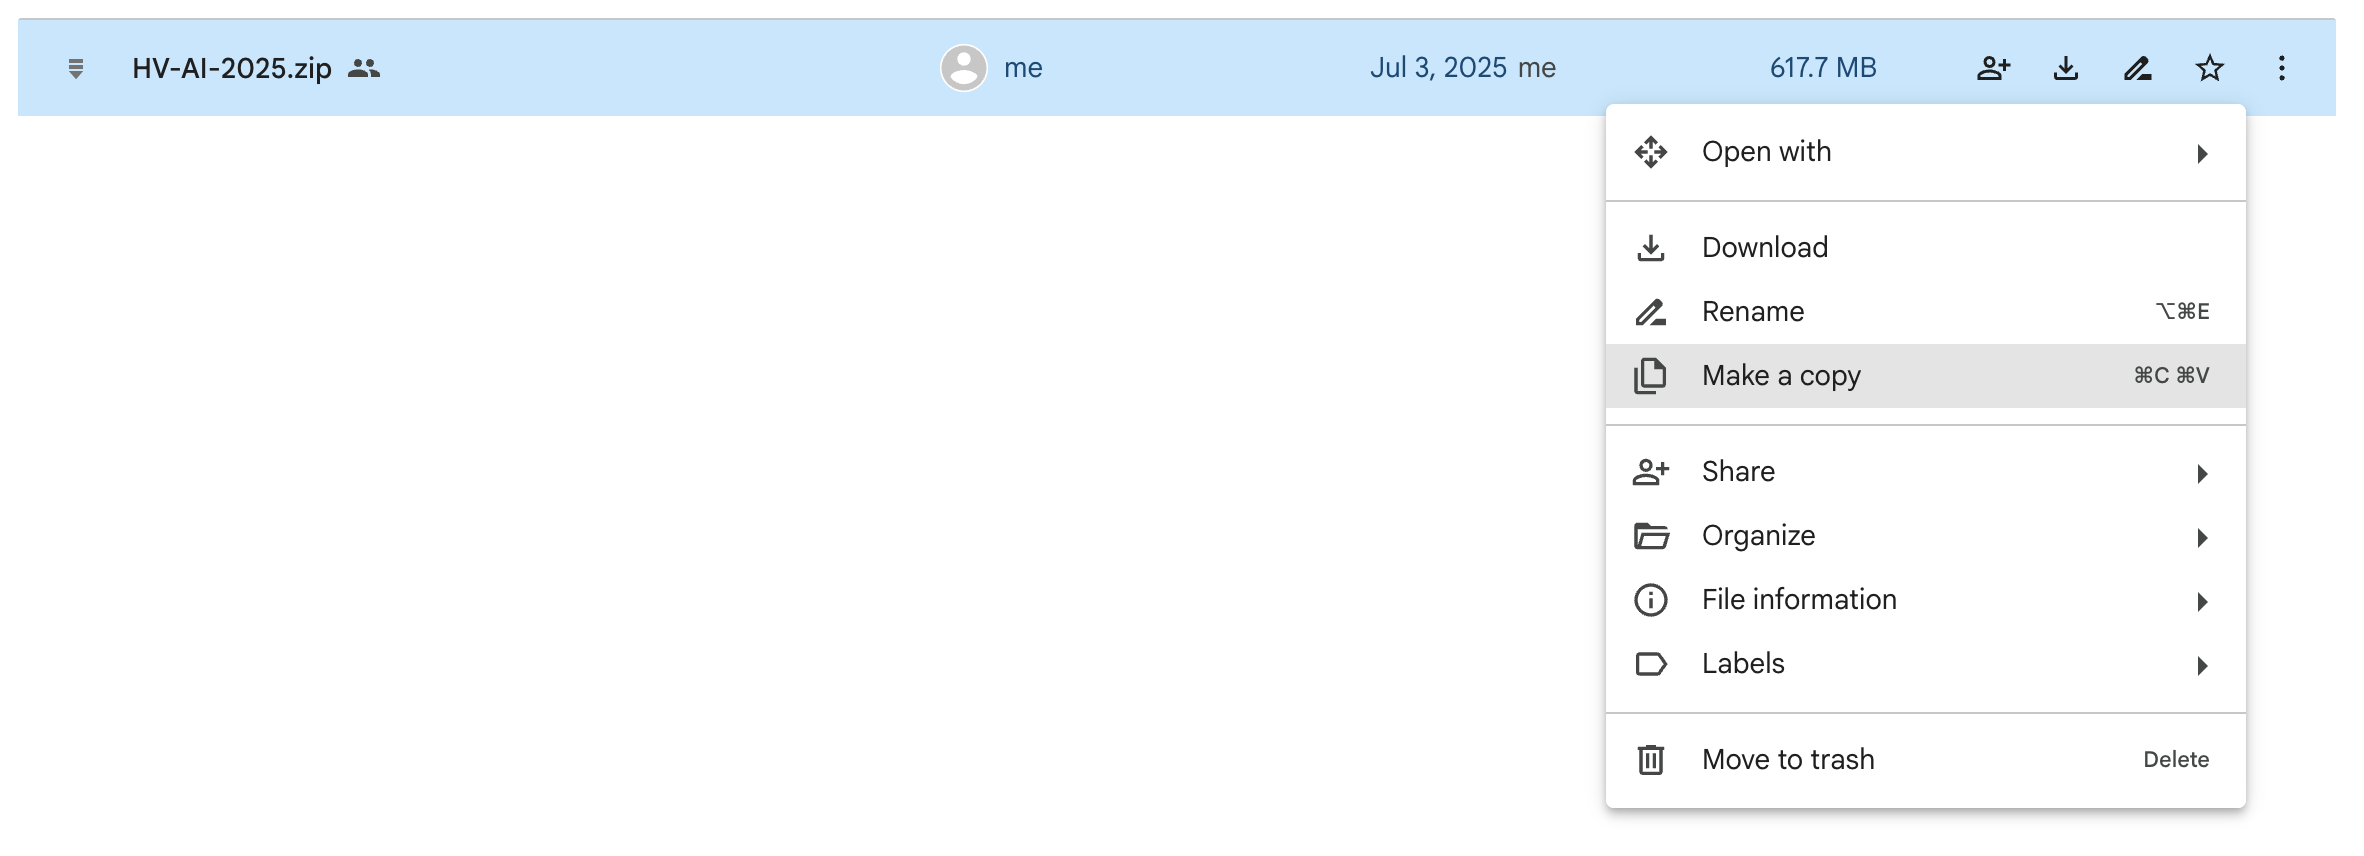

### Copy and unzip the training data (labelled + unlabelled)


In [ ]:

!cp "/content/drive/MyDrive/Copy of HV-AI-2025.zip" /content/HV-AI-2025.zip
!unzip -q HV-AI-2025.zip
!rm -rf /content/__MACOSX
!mv /content/HV-AI-2025/* /content/
!rm -rf /content/HV-AI-2025
!rm /content/HV-AI-2025.zip
!rm -rf /content/sample_data

# NOTE : "original_location_of_copy_in_drive" -> is a PLACEHOLDER. DO NOT RUN THIS AS IT IS.
# Please change this with your actual location/path where you have copied the data.
# Example, your path should look something like this -> "/content/drive/MyDrive/Copy of HV-AI-2025.zip"

### Check the data layout

In [ ]:
!ls /content
!find /content -maxdepth 3 -name "*.csv" -not -path "*/drive/*"
!find /content -maxdepth 3 -name "labels.csv" -not -path "*/drive/*" -exec head -5 {} \;
!for d in /content/*/; do echo "$d: $(find "$d" -type f | wc -l) files"; done

drive  labeled_data  unlabeled_data
/content/labeled_data/labeled_data.csv
/content/drive/: 511 files
/content/labeled_data/: 780 files
/content/unlabeled_data/: 14800 files


In [ ]:
!cp "/content/drive/MyDrive/Copy of HV-AI-2025-Test.zip" /content/HV-AI-2025-Test.zip
!unzip -q /content/HV-AI-2025-Test.zip -d /content
!rm -rf /content/__MACOSX
!mv /content/HV-AI-2025-Test/* /content/ 2>/dev/null
!rm -rf /content/HV-AI-2025-Test /content/HV-AI-2025-Test.zip
!ls /content
!for d in /content/*/; do echo "$d: $(find "$d" -type f | wc -l) files"; done

drive	      phase1_best.pt  phase2_r1.pt    test_images
labeled_data  phase1_v2.pt    teacher_rot.pt  unlabeled_data
/content/drive/: 515 files
/content/labeled_data/: 780 files
/content/test_images/: 10477 files
/content/unlabeled_data/: 14800 files


In [ ]:
n_img = sum(1 for p in Path("/content/test_images").rglob("*") if p.suffix.lower() in IMG_EXT)
print("Images the code will predict:", n_img)
!find /content/test_images -type f | sed 's/.*\.//' | sort | uniq -c

Images the code will predict: 10477
   9662 jpeg
    794 jpg
     21 png


# **Load/Preprocess **data****

### Setup and configuration: all hyperparameters in one place

In [ ]:
import os, random, time, shutil
from pathlib import Path
import numpy as np, pandas as pd, torch, torch.nn as nn
from PIL import Image
from torch.utils.data import Dataset, DataLoader, ConcatDataset
from torchvision import models, transforms
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

# ---------------- Config ----------------
DATA_ROOT     = "/content"
LABELED_DIR   = "/content/labeled_data"
LABELS_CSV    = "/content/labeled_data/labeled_data.csv"
UNLABELED_DIR = "/content/unlabeled_data"
CKPT_DIR      = "/content/drive/MyDrive/hv_ckpt"     # survives a Colab disconnect
os.makedirs(CKPT_DIR, exist_ok=True)

PRETRAINED  = True    # ImageNet-pretrained ResNet-18 (assumption stated in notebook)
USE_FLIP    = True    # set False if images are digits/text (mirroring changes meaning)
IMG_SIZE    = 224
BATCH_SIZE  = 64
EPOCHS      = 15      # Phase 1
EPOCHS_P2   = 10      # each Phase 2 round
LR          = 5e-4
VAL_FRAC    = 0.2
NUM_CLASSES = 10
LAB_REPEAT  = 3       # Phase 2: repeat labelled data so pseudo-labels don't drown it
SEED        = 42
IMG_EXT     = (".png", ".jpg", ".jpeg", ".bmp", ".webp")

device  = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = device.type == "cuda"

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

seed_everything(SEED)
print("Device:", device)

Device: cuda


### Load labels, index image files, stratified split, visual check of each class

Model, training loop (AdamW, one-cycle LR, label smoothing, AMP) and evaluation by mean per-class accuracy

                              img_name label
0  OIP--khXa4p9B3QV8JmsHX29hgHaEK.jpeg  cane
1  OIP--winA9MguCMZn6fdverPlwHaEK.jpeg  cane
2  OIP-0M8AAbNON2zvyCEB2WEhLQHaE8.jpeg  cane
3  OIP-16Mqc38MKBFr4a33cb_dFwHaGO.jpeg  cane
4  OIP-2sIPje3EMq9bP0vV2OGfmwHaEG.jpeg  cane 
shape: (779, 2)
Images found on disk: 779
Missing: 0

train 623 | val 156


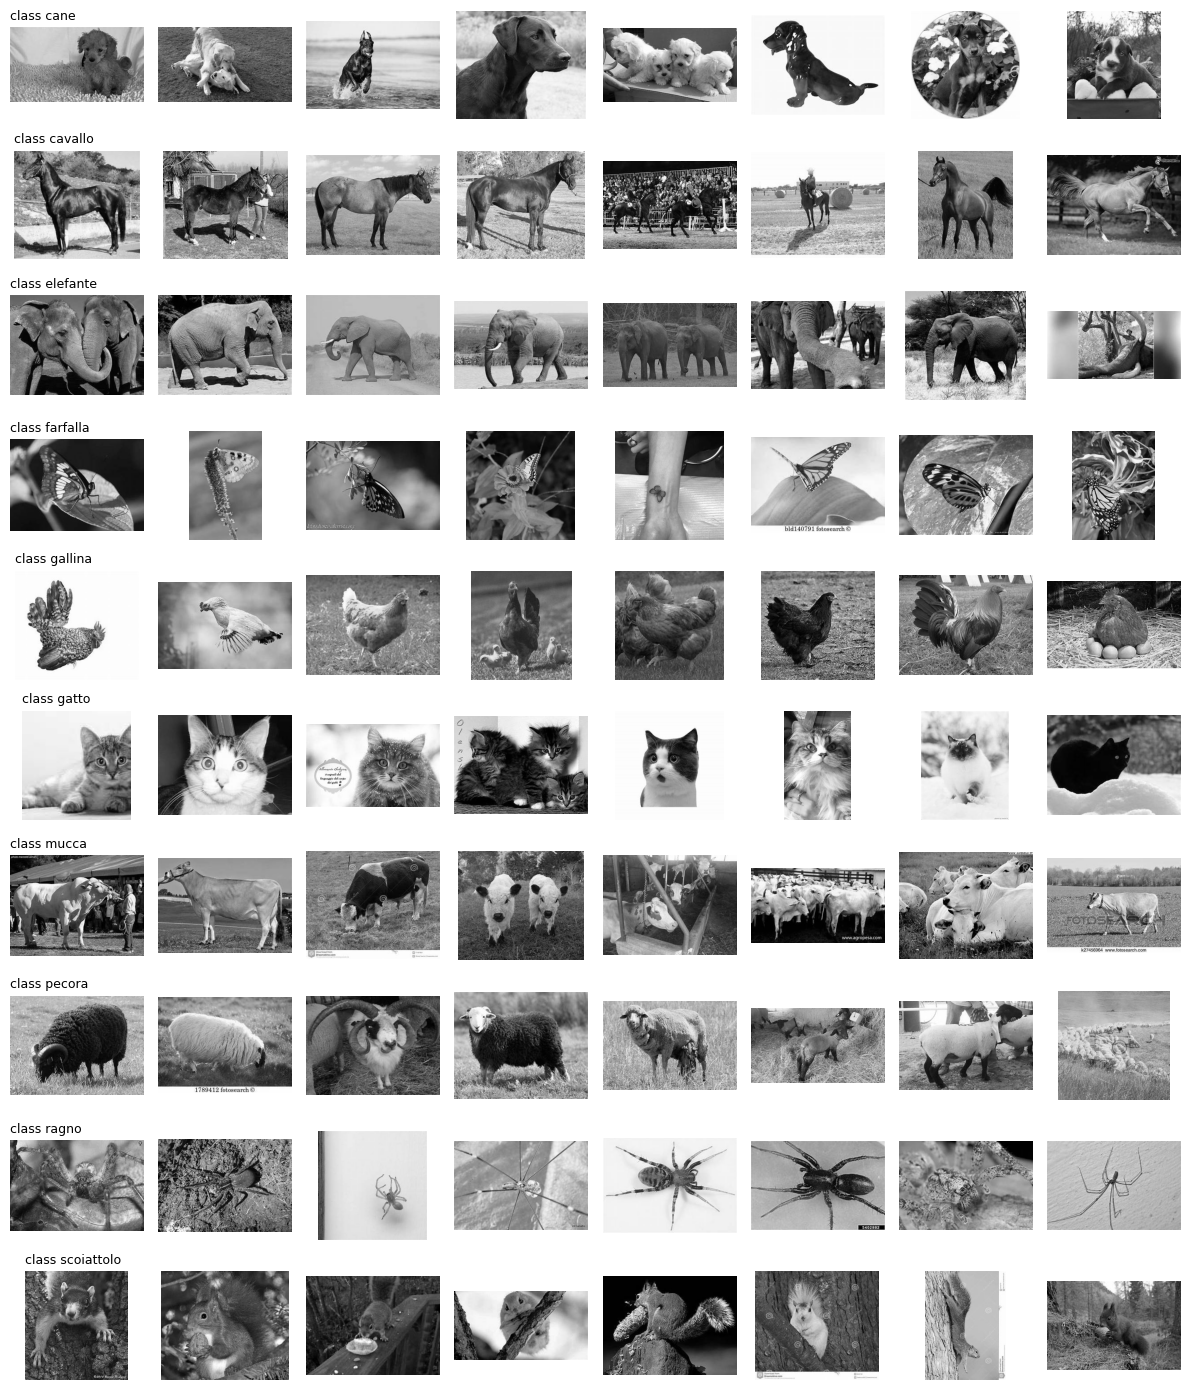

Example image size/mode: (300, 169) L


In [ ]:
df = pd.read_csv(LABELS_CSV)
print(df.head(), "\nshape:", df.shape)

FILE_COL, LABEL_COL = df.columns[0], df.columns[1]     # <-- check against head()

CLASSES = sorted(df[LABEL_COL].unique())                # original label values
assert len(CLASSES) == NUM_CLASSES, CLASSES
df["y"] = df[LABEL_COL].map({c: i for i, c in enumerate(CLASSES)})   # indices 0..9

# The CSV holds bare filenames; images may sit in a subfolder, so index every image by name
name_to_path = {p.name: str(p) for p in Path(LABELED_DIR).rglob("*") if p.suffix.lower() in IMG_EXT}
print("Images found on disk:", len(name_to_path))
df["filepath"] = df[FILE_COL].map(lambda n: name_to_path.get(os.path.basename(str(n))))
missing = df["filepath"].isna().sum()
print("Missing:", missing)
assert missing == 0, df[df["filepath"].isna()].head()

train_df, val_df = train_test_split(df, test_size=VAL_FRAC, stratify=df["y"], random_state=SEED)
print(f"\ntrain {len(train_df)} | val {len(val_df)}")

fig, axes = plt.subplots(NUM_CLASSES, 8, figsize=(12, 14))
for c in range(NUM_CLASSES):
    for ax, p in zip(axes[c], df[df["y"] == c]["filepath"].head(8)):
        ax.imshow(Image.open(p).convert("RGB")); ax.axis("off")
    axes[c][0].set_title(f"class {CLASSES[c]}", loc="left", fontsize=9)
plt.tight_layout(); plt.show()
with Image.open(df["filepath"].iloc[0]) as im:
    print("Example image size/mode:", im.size, im.mode)

### Transforms and datasets: labelled images held in memory; unlabelled and test images read from disk

In [ ]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
flip = [transforms.RandomHorizontalFlip()] if USE_FLIP else []

train_tf = transforms.Compose(
    [transforms.RandomResizedCrop(IMG_SIZE, scale=(0.6, 1.0))] + flip
    + [transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

strong_tf = transforms.Compose(      # Phase 2 pseudo-labelled images: heavier noise for the student
    [transforms.RandomResizedCrop(IMG_SIZE, scale=(0.5, 1.0))] + flip
    + [transforms.RandAugment(num_ops=2, magnitude=9),
       transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

def load_images(paths):
    imgs = []
    for p in paths:
        with Image.open(p) as im:
            imgs.append(im.convert("RGB"))
    return imgs

class ImageDataset(Dataset):
    """In-memory images. Returns (image, label), or (image, index) when unlabelled."""
    def __init__(self, images, labels, transform):
        self.images, self.labels, self.transform = images, labels, transform
    def __len__(self):
        return len(self.images)
    def __getitem__(self, i):
        x = self.transform(self.images[i])
        return (x, self.labels[i]) if self.labels is not None else (x, i)

class PathDataset(Dataset):
    """Reads images from disk on demand (used for the 14.8k unlabelled + test images)."""
    def __init__(self, paths, labels, transform):
        self.paths, self.labels, self.transform = list(paths), labels, transform
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        with Image.open(self.paths[i]) as im:
            x = self.transform(im.convert("RGB"))
        return (x, self.labels[i]) if self.labels is not None else (x, i)

train_imgs = load_images(train_df["filepath"])
val_imgs   = load_images(val_df["filepath"])

train_loader = DataLoader(ImageDataset(train_imgs, train_df["y"].tolist(), train_tf),
                          batch_size=BATCH_SIZE, shuffle=True, num_workers=2,
                          pin_memory=True, drop_last=True)
val_loader   = DataLoader(ImageDataset(val_imgs, val_df["y"].tolist(), eval_tf),
                          batch_size=128, shuffle=False, num_workers=2, pin_memory=True)
print("Loaded", len(train_imgs) + len(val_imgs), "labelled images")

Loaded 779 labelled images


# **Model initialization/Training**

In [ ]:
def build_model():
    weights = models.ResNet18_Weights.DEFAULT if PRETRAINED else None
    m = models.resnet18(weights=weights)
    m.fc = nn.Linear(m.fc.in_features, NUM_CLASSES)
    return m.to(device)

def evaluate(model, loader):
    model.eval(); preds, labels = [], []
    with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16, enabled=USE_AMP):
        for x, y in loader:
            preds.append(model(x.to(device, non_blocking=True)).argmax(1).cpu())
            labels.append(y)
    preds, labels = torch.cat(preds), torch.cat(labels)
    acc = (preds == labels).float().mean().item()
    per_class = [(preds[labels == c] == c).float().mean().item() for c in range(NUM_CLASSES)]
    return acc, per_class

def train_model(model, train_loader, val_loader, epochs, lr, ckpt_path):
    """AdamW + one-cycle LR + label smoothing + mixed precision.
    Keeps the checkpoint with the best mean per-class validation accuracy."""
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=lr,
                                                    total_steps=epochs * len(train_loader))
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    best = -1.0
    for ep in range(epochs):
        model.train(); t0 = time.time(); run_loss = 0.0
        for x, y in train_loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast("cuda", dtype=torch.float16, enabled=USE_AMP):
                loss = criterion(model(x), y)
            scaler.scale(loss).backward()
            scaler.step(optimizer); scaler.update(); scheduler.step()
            run_loss += loss.item()
        acc, per_class = evaluate(model, val_loader)
        bal = sum(per_class) / NUM_CLASSES
        if bal > best:
            best = bal; torch.save(model.state_dict(), ckpt_path)
        print(f"ep {ep+1}/{epochs} | loss {run_loss/len(train_loader):.3f} | val acc {acc:.4f} "
              f"| mean per-class {bal:.4f} | worst class {min(per_class):.3f} | {time.time()-t0:.0f}s")
    model.load_state_dict(torch.load(ckpt_path))
    acc, per_class = evaluate(model, val_loader)
    print(f"\nBest: val acc {acc:.4f} | per class:",
          [f"{CLASSES[c]}:{a:.2f}" for c, a in enumerate(per_class)])
    return model, best

def predict_probs(model, loader):
    """Softmax probabilities, averaged with a horizontal-flip view if flips are label-safe."""
    model.eval(); out = []
    with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16, enabled=USE_AMP):
        for x, _ in loader:
            x = x.to(device, non_blocking=True)
            p = model(x).float().softmax(1)
            if USE_FLIP:
                p = (p + model(torch.flip(x, dims=[3])).float().softmax(1)) / 2
            out.append(p.cpu())
    return torch.cat(out)

### Phase 1 v1: baseline fine-tuning

In [ ]:
model_p1, p1_score = train_model(build_model(), train_loader, val_loader, EPOCHS, LR, "phase1_best.pt")
shutil.copy("phase1_best.pt", CKPT_DIR)
print("Phase 1 mean per-class val acc:", round(p1_score, 4))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 131MB/s]


ep 1/15 | loss 2.270 | val acc 0.3590 | mean per-class 0.3410 | worst class 0.000 | 4s
ep 2/15 | loss 1.351 | val acc 0.6154 | mean per-class 0.4816 | worst class 0.000 | 2s
ep 3/15 | loss 0.805 | val acc 0.8013 | mean per-class 0.7646 | worst class 0.455 | 2s
ep 4/15 | loss 0.652 | val acc 0.7885 | mean per-class 0.7607 | worst class 0.455 | 3s
ep 5/15 | loss 0.600 | val acc 0.7949 | mean per-class 0.7491 | worst class 0.455 | 3s
ep 6/15 | loss 0.578 | val acc 0.8013 | mean per-class 0.7673 | worst class 0.273 | 2s
ep 7/15 | loss 0.570 | val acc 0.8333 | mean per-class 0.7969 | worst class 0.562 | 2s
ep 8/15 | loss 0.553 | val acc 0.8333 | mean per-class 0.8060 | worst class 0.600 | 2s
ep 9/15 | loss 0.544 | val acc 0.8462 | mean per-class 0.8256 | worst class 0.600 | 2s
ep 10/15 | loss 0.536 | val acc 0.8846 | mean per-class 0.8463 | worst class 0.600 | 4s
ep 11/15 | loss 0.535 | val acc 0.8654 | mean per-class 0.8246 | worst class 0.600 | 2s
ep 12/15 | loss 0.530 | val acc 0.8590 | 

### Phase 1 v2: class-balanced sampling

In [ ]:
from torch.utils.data import WeightedRandomSampler

counts = np.bincount(train_df["y"], minlength=NUM_CLASSES)
print("Train images per class:", dict(zip(CLASSES, counts.tolist())))
sample_w = 1.0 / counts[train_df["y"].values]            # rare classes drawn more often
sampler = WeightedRandomSampler(torch.as_tensor(sample_w, dtype=torch.double),
                                num_samples=len(train_df), replacement=True)
balanced_loader = DataLoader(ImageDataset(train_imgs, train_df["y"].tolist(), train_tf),
                             batch_size=BATCH_SIZE, sampler=sampler, num_workers=2,
                             pin_memory=True, drop_last=True)

model_v2, v2_score = train_model(build_model(), balanced_loader, val_loader, 30, LR, "phase1_v2.pt")
if v2_score > p1_score:                                   # keep whichever is better
    model_p1, p1_score = model_v2, v2_score
    shutil.copy("phase1_v2.pt", f"{CKPT_DIR}/phase1_best.pt")
print("Phase 1 model kept: mean per-class", round(p1_score, 4))

Train images per class: {'cane': 116, 'cavallo': 62, 'elefante': 35, 'farfalla': 50, 'gallina': 74, 'gatto': 40, 'mucca': 44, 'pecora': 43, 'ragno': 115, 'scoiattolo': 44}
ep 1/30 | loss 2.205 | val acc 0.2885 | mean per-class 0.3052 | worst class 0.000 | 4s
ep 2/30 | loss 1.647 | val acc 0.5577 | mean per-class 0.5405 | worst class 0.000 | 3s
ep 3/30 | loss 1.071 | val acc 0.6731 | mean per-class 0.6249 | worst class 0.182 | 3s
ep 4/30 | loss 0.809 | val acc 0.7949 | mean per-class 0.7705 | worst class 0.545 | 2s
ep 5/30 | loss 0.669 | val acc 0.8141 | mean per-class 0.7760 | worst class 0.600 | 2s
ep 6/30 | loss 0.622 | val acc 0.8077 | mean per-class 0.7642 | worst class 0.364 | 2s
ep 7/30 | loss 0.593 | val acc 0.7949 | mean per-class 0.7734 | worst class 0.455 | 2s
ep 8/30 | loss 0.584 | val acc 0.8397 | mean per-class 0.8222 | worst class 0.600 | 4s
ep 9/30 | loss 0.575 | val acc 0.7756 | mean per-class 0.7505 | worst class 0.455 | 3s
ep 10/30 | loss 0.568 | val acc 0.7949 | mean

**Phase 2: Semi-supervised learning**

In [ ]:
from torch.utils.data import WeightedRandomSampler

unl_paths = sorted(str(p) for p in Path(UNLABELED_DIR).rglob("*") if p.suffix.lower() in IMG_EXT)
print("Unlabelled images:", len(unl_paths))

def label_unlabeled(teacher): #trained model acts as the teacher
    """Teacher predicts class probabilities for every unlabelled image."""
    t0 = time.time()
    loader = DataLoader(PathDataset(unl_paths, None, eval_tf), batch_size=256,
                        shuffle=False, num_workers=2, pin_memory=True)
    probs = predict_probs(teacher, loader)
    conf, pred = probs.max(1)
    print(f"Labelled {len(unl_paths)} images in {time.time() - t0:.0f}s")
    print("Predicted per class:", torch.bincount(pred, minlength=NUM_CLASSES).tolist())
    print("Median conf per class:", [round(conf[pred == c].median().item(), 2) if (pred == c).any()
                                     else None for c in range(NUM_CLASSES)])
    return probs

def select_pseudo(probs, cap=500, frac=0.5):
    """Class-relative selection: within each predicted class keep the most confident
    `frac` share, at most `cap` images. Confidence levels differ a lot between classes
    (spiders are easy, cats are not), so one global threshold would starve some classes."""
    conf, pred = probs.max(1)
    keep = []
    for c in range(NUM_CLASSES):
        idx = torch.where(pred == c)[0]
        k = min(cap, int(frac * len(idx)))
        keep.append(idx[conf[idx].argsort(descending=True)][:k])
    keep = torch.cat(keep)
    print(f"Kept {len(keep)} | per class {torch.bincount(pred[keep], minlength=NUM_CLASSES).tolist()} "
          f"| mean conf {conf[keep].mean():.3f}")
    return keep.tolist(), pred[keep].tolist()

def train_student(idx, labels, ckpt_path, epochs):
    """Fresh ResNet-18 trained on labelled + pseudo-labelled images, class-balanced sampling."""
    pseudo_ds  = PathDataset([unl_paths[i] for i in idx], labels, strong_tf)
    labeled_ds = ImageDataset(train_imgs, train_df["y"].tolist(), train_tf)
    mixed   = ConcatDataset([labeled_ds] * LAB_REPEAT + [pseudo_ds])
    mixed_y = np.array(train_df["y"].tolist() * LAB_REPEAT + list(labels))
    w = 1.0 / np.bincount(mixed_y, minlength=NUM_CLASSES)[mixed_y]
    sampler = WeightedRandomSampler(torch.as_tensor(w, dtype=torch.double),
                                    num_samples=len(mixed), replacement=True)
    loader = DataLoader(mixed, batch_size=BATCH_SIZE, sampler=sampler, num_workers=2,
                        pin_memory=True, drop_last=True)
    print("Student trains on", len(mixed), "images per epoch")
    return train_model(build_model(), loader, val_loader, epochs, LR, ckpt_path)

Unlabelled images: 14800


In [ ]:
EPOCHS_P2 = 15
teacher_probs = label_unlabeled(model_p1)
idx, labels = select_pseudo(teacher_probs, cap=500, frac=0.5)
model_r1, r1_score = train_student(idx, labels, "phase2_r1.pt", epochs=EPOCHS_P2)
shutil.copy("phase2_r1.pt", CKPT_DIR)
P2_BEST, p2_score = "phase2_r1.pt", r1_score
print(f"Phase 1: {p1_score:.4f} -> Phase 2 round 1: {r1_score:.4f}")

Labelled 14800 images in 59s
Predicted per class: [319, 179, 41, 1819, 2068, 6033, 394, 50, 3887, 10]
Median conf per class: [0.29, 0.26, 0.23, 0.27, 0.27, 0.29, 0.23, 0.23, 0.34, 0.23]
Kept 2495 | per class [159, 89, 20, 500, 500, 500, 197, 25, 500, 5] | mean conf 0.486
Student trains on 4364 images per epoch
ep 1/15 | loss 1.585 | val acc 0.8077 | mean per-class 0.8041 | worst class 0.600 | 20s
ep 2/15 | loss 0.804 | val acc 0.8654 | mean per-class 0.8528 | worst class 0.600 | 18s
ep 3/15 | loss 0.744 | val acc 0.7500 | mean per-class 0.7237 | worst class 0.273 | 20s
ep 4/15 | loss 0.773 | val acc 0.7949 | mean per-class 0.7855 | worst class 0.545 | 19s
ep 5/15 | loss 0.737 | val acc 0.7821 | mean per-class 0.7582 | worst class 0.400 | 18s
ep 6/15 | loss 0.686 | val acc 0.7372 | mean per-class 0.6997 | worst class 0.455 | 18s
ep 7/15 | loss 0.678 | val acc 0.7628 | mean per-class 0.7656 | worst class 0.611 | 20s
ep 8/15 | loss 0.629 | val acc 0.7949 | mean per-class 0.7484 | worst cl

Diagnosis: comparing unlabelled vs labelled images

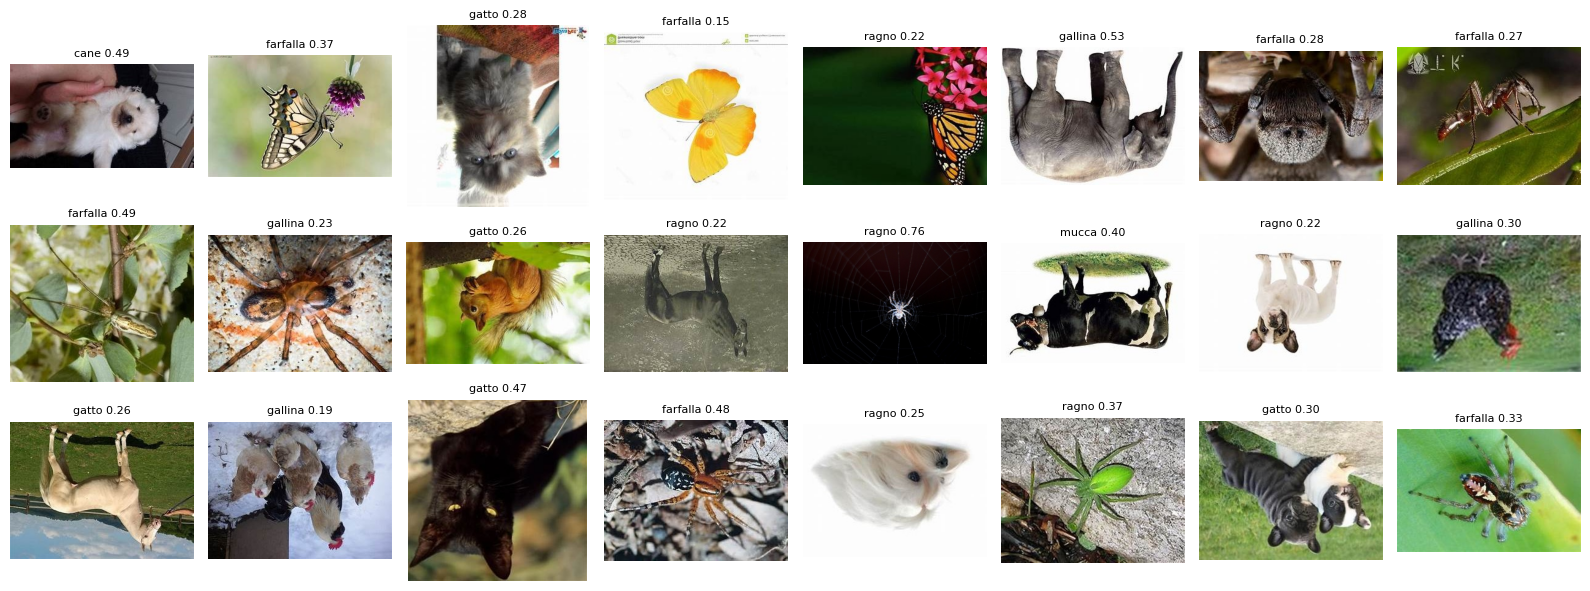

Unlabelled: ([((300, 225), 52), ((300, 200), 30), ((300, 300), 21), ((300, 169), 12)], {'RGB': 300})
Labelled:   ([((300, 225), 53), ((300, 200), 36), ((300, 169), 17), ((300, 300), 16)], {'L': 300})
Teacher median conf on VAL: 0.74


In [ ]:
import collections

# 1) What do the unlabelled images look like, and what does the teacher call them?
conf_u, pred_u = teacher_probs.max(1)
ids = random.sample(range(len(unl_paths)), 24)
fig, axes = plt.subplots(3, 8, figsize=(16, 6))
for ax, i in zip(axes.flat, ids):
    ax.imshow(Image.open(unl_paths[i]).convert("RGB")); ax.axis("off")
    ax.set_title(f"{CLASSES[pred_u[i]]} {conf_u[i]:.2f}", fontsize=8)
plt.tight_layout(); plt.show()

# 2) Size / colour mode of unlabelled vs labelled images
def size_mode_stats(paths, n=300):
    sizes, modes = collections.Counter(), collections.Counter()
    for p in random.sample(list(paths), min(n, len(paths))):
        with Image.open(p) as im:
            sizes[im.size] += 1; modes[im.mode] += 1
    return sizes.most_common(4), dict(modes)
print("Unlabelled:", size_mode_stats(unl_paths))
print("Labelled:  ", size_mode_stats(df["filepath"]))

# 3) Teacher confidence on validation, for comparison with the 0.23-0.34 above
val_probs = predict_probs(model_p1, val_loader)
print("Teacher median conf on VAL:", round(val_probs.max(1).values.median().item(), 3))

Domain shift found: labelled = greyscale and upright, unlabelled = colour and rotated. Fix: greyscale everything, rotation augmentation, 4-rotation averaging at prediction time, and model selection on rotated validation."

### Fix: greyscale, rotation augmentation, 4-rotation averaging, rotated validation

In [ ]:
class RandomRot90:
    """Rotate a PIL image by a random multiple of 90 degrees."""
    def __call__(self, img):
        k = random.randint(0, 3)
        return img.rotate(90 * k, expand=True) if k else img

GRAY = transforms.Grayscale(num_output_channels=3)
flip = [transforms.RandomHorizontalFlip()] if USE_FLIP else []

train_tf = transforms.Compose(
    [GRAY, RandomRot90(), transforms.RandomResizedCrop(IMG_SIZE, scale=(0.6, 1.0))] + flip
    + [transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
strong_tf = transforms.Compose(
    [GRAY, RandomRot90(), transforms.RandomResizedCrop(IMG_SIZE, scale=(0.5, 1.0))] + flip
    + [transforms.RandAugment(num_ops=2, magnitude=9), transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
eval_tf = transforms.Compose(
    [GRAY, transforms.Resize((IMG_SIZE, IMG_SIZE)), transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

def predict_probs(model, loader):
    """Softmax averaged over 4 rotations (x2 with horizontal flip)."""
    model.eval(); out = []
    with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16, enabled=USE_AMP):
        for x, _ in loader:
            x = x.to(device, non_blocking=True)
            views = [torch.rot90(x, k, dims=(2, 3)) for k in range(4)]
            if USE_FLIP:
                views += [torch.flip(v, dims=[3]) for v in views]
            p = sum(model(v).float().softmax(1) for v in views) / len(views)
            out.append(p.cpu())
    return torch.cat(out)

# Validation that resembles the unlabelled data: each val image in all 4 orientations
val_rot_imgs, val_rot_y = [], []
for img, y in zip(val_imgs, val_df["y"].tolist()):
    for k in range(4):
        val_rot_imgs.append(img.rotate(90 * k, expand=True) if k else img)
        val_rot_y.append(y)
val_rot_loader = DataLoader(ImageDataset(val_rot_imgs, val_rot_y, eval_tf),
                            batch_size=128, shuffle=False, num_workers=2, pin_memory=True)

# How much does rotation hurt the Phase 1 model, and how much does rotation-averaging recover?
acc, pc = evaluate(model_p1, val_rot_loader)
print(f"Phase 1 on rotated val, single view : acc {acc:.4f} | mean per-class {sum(pc)/NUM_CLASSES:.4f}")
p = predict_probs(model_p1, val_rot_loader)
print(f"Phase 1 on rotated val, 4-rot average: acc {(p.argmax(1) == torch.tensor(val_rot_y)).float().mean():.4f}")

val_loader = val_rot_loader   # from here on, select models on rotation-robust validation

Phase 1 on rotated val, single view : acc 0.6538 | mean per-class 0.6117
Phase 1 on rotated val, 4-rot average: acc 0.7821


### Rotation-robust teacher (labelled data only)

In [ ]:
teacher_loader = DataLoader(ImageDataset(train_imgs, train_df["y"].tolist(), train_tf),
                            batch_size=BATCH_SIZE, sampler=sampler, num_workers=2,
                            pin_memory=True, drop_last=True)
teacher_rot, t_score = train_model(build_model(), teacher_loader, val_loader, 40, LR, "teacher_rot.pt")
shutil.copy("teacher_rot.pt", CKPT_DIR)

ep 1/40 | loss 2.270 | val acc 0.2772 | mean per-class 0.2236 | worst class 0.000 | 5s
ep 2/40 | loss 1.956 | val acc 0.3798 | mean per-class 0.2958 | worst class 0.000 | 6s
ep 3/40 | loss 1.559 | val acc 0.5224 | mean per-class 0.4310 | worst class 0.000 | 5s
ep 4/40 | loss 1.244 | val acc 0.5897 | mean per-class 0.5003 | worst class 0.045 | 4s
ep 5/40 | loss 0.940 | val acc 0.7147 | mean per-class 0.6610 | worst class 0.295 | 6s
ep 6/40 | loss 0.831 | val acc 0.7035 | mean per-class 0.6600 | worst class 0.295 | 5s
ep 7/40 | loss 0.740 | val acc 0.6490 | mean per-class 0.6577 | worst class 0.219 | 5s
ep 8/40 | loss 0.710 | val acc 0.6891 | mean per-class 0.6593 | worst class 0.205 | 6s
ep 9/40 | loss 0.722 | val acc 0.6458 | mean per-class 0.5990 | worst class 0.136 | 4s
ep 10/40 | loss 0.693 | val acc 0.6843 | mean per-class 0.6809 | worst class 0.469 | 4s
ep 11/40 | loss 0.710 | val acc 0.6490 | mean per-class 0.6410 | worst class 0.386 | 6s
ep 12/40 | loss 0.697 | val acc 0.6314 | 

'/content/drive/MyDrive/hv_ckpt/teacher_rot.pt'

In [ ]:
teacher_probs = label_unlabeled(teacher_rot)
idx, labels = select_pseudo(teacher_probs, cap=500, frac=0.5)
model_r1, r1_score = train_student(idx, labels, "phase2_r1.pt", epochs=15)
shutil.copy("phase2_r1.pt", CKPT_DIR)
P2_BEST, p2_score = "phase2_r1.pt", r1_score
print(f"Rotation-robust teacher: {t_score:.4f} -> student: {r1_score:.4f}")

Labelled 14800 images in 78s
Predicted per class: [2294, 1508, 813, 1236, 1728, 998, 1409, 1066, 2771, 977]
Median conf per class: [0.7, 0.65, 0.67, 0.84, 0.73, 0.78, 0.61, 0.53, 0.85, 0.68]
Kept 4893 | per class [500, 500, 406, 500, 500, 499, 500, 500, 500, 488] | mean conf 0.865
Student trains on 6762 images per epoch
ep 1/15 | loss 1.388 | val acc 0.7163 | mean per-class 0.7095 | worst class 0.477 | 38s
ep 2/15 | loss 0.724 | val acc 0.7500 | mean per-class 0.7337 | worst class 0.438 | 41s
ep 3/15 | loss 0.718 | val acc 0.6971 | mean per-class 0.7166 | worst class 0.422 | 38s
ep 4/15 | loss 0.717 | val acc 0.6955 | mean per-class 0.7015 | worst class 0.528 | 40s
ep 5/15 | loss 0.697 | val acc 0.7051 | mean per-class 0.6762 | worst class 0.432 | 39s
ep 6/15 | loss 0.662 | val acc 0.7083 | mean per-class 0.6999 | worst class 0.525 | 38s
ep 7/15 | loss 0.630 | val acc 0.7228 | mean per-class 0.7224 | worst class 0.455 | 42s
ep 8/15 | loss 0.611 | val acc 0.7516 | mean per-class 0.7641 

In [ ]:
def tta_scores(probs, y):
    pred = probs.argmax(1)
    acc = (pred == y).float().mean().item()
    pc = [(pred[y == c] == c).float().mean().item() for c in range(NUM_CLASSES)]
    return acc, sum(pc) / NUM_CLASSES, min(pc)

y_rot = torch.tensor(val_rot_y)
probs = {
    "Phase 1 (upright model)": predict_probs(model_p1, val_rot_loader),
    "Rot-robust teacher":      predict_probs(teacher_rot, val_rot_loader),
    "Phase 2 student":         predict_probs(model_r1, val_rot_loader),
}
probs["Ensemble student+teacher"] = (probs["Phase 2 student"] + probs["Rot-robust teacher"]) / 2
probs["Ensemble student+phase1"]  = (probs["Phase 2 student"] + probs["Phase 1 (upright model)"]) / 2
for name, p in probs.items():
    acc, bal, worst = tta_scores(p, y_rot)
    print(f"{name:26s} acc {acc:.4f} | mean per-class {bal:.4f} | worst class {worst:.3f}")

Phase 1 (upright model)    acc 0.7821 | mean per-class 0.7485 | worst class 0.545
Rot-robust teacher         acc 0.7692 | mean per-class 0.7722 | worst class 0.600
Phase 2 student            acc 0.8269 | mean per-class 0.8127 | worst class 0.700
Ensemble student+teacher   acc 0.8462 | mean per-class 0.8308 | worst class 0.700
Ensemble student+phase1    acc 0.8429 | mean per-class 0.8234 | worst class 0.700


# **Model Inference**

In [ ]:
def make_submission(models, test_dir, out_csv, name, email):
    """Predict every test image (rotation-averaged, optionally ensembled), write CSV, submit."""
    if not isinstance(models, (list, tuple)):
        models = [models]
    test_paths = sorted(p for p in Path(test_dir).rglob("*") if p.suffix.lower() in IMG_EXT)
    loader = DataLoader(PathDataset(test_paths, None, eval_tf), batch_size=128,
                        shuffle=False, num_workers=2)
    probs = sum(predict_probs(m, loader) for m in models) / len(models)
    sub = pd.DataFrame({
        "path": [os.path.relpath(p, "/content") for p in test_paths],
        "predicted_label": [str(CLASSES[i]) for i in probs.argmax(1).tolist()],
    })
    assert len(sub) == len(test_paths) and sub["path"].is_unique
    sub.to_csv(out_csv, index=False)
    print(sub.head(), "\n", sub["predicted_label"].value_counts().sort_index())
    print("Accuracy:", send_results_for_evaluation(name, out_csv, email))

In [ ]:
TEST_DIR = "/content/test_images"
NAME, EMAIL = "P.V. Sathyanarayanan", "pvsathyn2005@gmail.com"

# Phase 1: labelled-only model (greyscale + rotation-averaging applied at prediction time)
m1 = build_model(); m1.load_state_dict(torch.load(f"{CKPT_DIR}/phase1_best.pt"))
make_submission(m1, TEST_DIR, "phase1_predictions.csv", NAME, EMAIL)

# Phase 2: Noisy Student student + rotation-robust teacher, predictions averaged
t = build_model(); t.load_state_dict(torch.load(f"{CKPT_DIR}/teacher_rot.pt"))
s = build_model(); s.load_state_dict(torch.load(f"{CKPT_DIR}/{P2_BEST}"))
make_submission([s, t], TEST_DIR, "phase2_predictions.csv", NAME, EMAIL)

                      path predicted_label
0  test_images/0_1034.jpeg           gatto
1  test_images/0_1045.jpeg           gatto
2  test_images/0_1085.jpeg           gatto
3   test_images/0_110.jpeg            cane
4  test_images/0_1104.jpeg           gatto 
 predicted_label
cane          1658
cavallo        964
elefante       442
farfalla      1027
gallina       1651
gatto          727
mucca          427
pecora         437
ragno         2477
scoiattolo     667
Name: count, dtype: int64
Accuracy: {'accuracy': 80.46}
                      path predicted_label
0  test_images/0_1034.jpeg           gatto
1  test_images/0_1045.jpeg           gatto
2  test_images/0_1085.jpeg           gatto
3   test_images/0_110.jpeg           gatto
4  test_images/0_1104.jpeg           gatto 
 predicted_label
cane          1560
cavallo       1151
elefante       610
farfalla       854
gallina       1222
gatto          679
mucca          902
pecora         925
ragno         1938
scoiattolo     636
Name: count,

In [ ]:
!cp phase2_predictions.csv phase2_predictions_v1.csv

In [ ]:
probs["Ensemble all three"] = (probs["Phase 2 student"] + probs["Rot-robust teacher"]
                               + probs["Phase 1 (upright model)"]) / 3
acc, bal, worst = tta_scores(probs["Ensemble all three"], y_rot)
print(f"Ensemble all three  acc {acc:.4f} | mean per-class {bal:.4f} | worst class {worst:.3f}")

Ensemble all three  acc 0.8526 | mean per-class 0.8370 | worst class 0.700


In [ ]:
make_submission([s, t, m1], TEST_DIR, "phase2_predictions.csv", NAME, EMAIL)

                      path predicted_label
0  test_images/0_1034.jpeg           gatto
1  test_images/0_1045.jpeg           gatto
2  test_images/0_1085.jpeg           gatto
3   test_images/0_110.jpeg           gatto
4  test_images/0_1104.jpeg           gatto 
 predicted_label
cane          1587
cavallo       1142
elefante       600
farfalla       860
gallina       1261
gatto          674
mucca          848
pecora         860
ragno         1997
scoiattolo     648
Name: count, dtype: int64
Accuracy: {'accuracy': 85.04}


**Predicting at higher input resolution (224 vs 256 vs 288)**

In [ ]:
def val_rot_probs_at(size, models):
    """Rotation-averaged ensemble probabilities on rotated val, predicted at a given input size."""
    tf = transforms.Compose([GRAY, transforms.Resize((size, size)),
                             transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
    loader = DataLoader(ImageDataset(val_rot_imgs, val_rot_y, tf), batch_size=128,
                        shuffle=False, num_workers=2)
    return sum(predict_probs(m, loader) for m in models) / len(models)

for size in (224, 256, 288):
    acc, bal, worst = tta_scores(val_rot_probs_at(size, [s, t, m1]), y_rot)
    print(f"size {size}: acc {acc:.4f} | mean per-class {bal:.4f} | worst class {worst:.3f}")

size 224: acc 0.8526 | mean per-class 0.8370 | worst class 0.700
size 256: acc 0.8558 | mean per-class 0.8433 | worst class 0.700
size 288: acc 0.8526 | mean per-class 0.8406 | worst class 0.700


In [ ]:
eval_tf = transforms.Compose([GRAY, transforms.Resize((256, 256)),
                              transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
!cp phase2_predictions.csv phase2_predictions_v2.csv          # back up the 85.04% file
make_submission([s, t, m1], TEST_DIR, "phase2_predictions.csv", NAME, EMAIL)

                      path predicted_label
0  test_images/0_1034.jpeg           gatto
1  test_images/0_1045.jpeg           gatto
2  test_images/0_1085.jpeg           gatto
3   test_images/0_110.jpeg           gatto
4  test_images/0_1104.jpeg           gatto 
 predicted_label
cane          1669
cavallo       1080
elefante       594
farfalla       855
gallina       1245
gatto          698
mucca          828
pecora         839
ragno         1992
scoiattolo     677
Name: count, dtype: int64
Accuracy: {'accuracy': 86.31}


### Checking 256×256 for the Phase 1 model alone (worse – not used)

In [ ]:
for size in (224, 256):
    acc, bal, worst = tta_scores(val_rot_probs_at(size, [m1]), y_rot)
    print(f"Phase 1 at {size}: acc {acc:.4f} | mean per-class {bal:.4f}")

Phase 1 at 224: acc 0.7821 | mean per-class 0.7485
Phase 1 at 256: acc 0.7628 | mean per-class 0.7240


# **Helper Functions**

In [ ]:
import requests

def send_results_for_evaluation(name, csv_file, email):
    url = "http://43.205.49.236:5050/inference"
    files = {'file': open(csv_file, 'rb')}
    data = {'email': email, 'name':name}
    response = requests.post(url, files=files, data=data)
    return response.json()



# ***Test Inference***


This function is used to save the csv file and send it to the evaluation server.

Format of CSV file (Follow the header names strictly):

          path (str)               predicted_label(str)
    test_data/images/xx.jpg               class_1         
    test_data/images/yy.jpg               class_2         
             :                               :                          
             :                               :                          

Once the prediction file is saved as shown in the above format, you can send it to the evaluation server along with your email.

Caution: check your **email** before executing the cell.

IMPORTANT NOTE: "class_1", "class_2" are just placeholders. They are not actual class names. Replace them with actual class names.


In [ ]:
print('Accuracy: ')
print(send_results_for_evaluation('name', 'path to pred.csv', 'your_email'))